In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams.update({
    'figure.dpi' : 300,
    'text.usetex' : True,
    'font.size' : 16,
    'font.family' : "sans-serif",
    'font.sans-serif' : 'Helvetica',
    'font.serif' : 'Palatino',
    'legend.fontsize' : 16,
    'axes.titlesize' : 16
})
import numpy as np
import polars as pl
import os
from pathlib import Path

plt.style.use('tableau-colorblind10')
colors = np.array(plt.rcParams["axes.prop_cycle"].by_key()["color"])

In [2]:
data_params_df = pl.read_csv("../data/data_params.csv", columns = ["simulation_id", "ID", "chi_macrophageToCSF", "halfMaximalExtravasationCsf1Conc"])
data_params_df.columns = ["simulation_id", "ID", "chi_cm", "c_half"]
kwargs = { 
        "Stroma" : { "c" : "C0", "marker" : ".", },
        "Vessel" : { "c" : "C0", "marker" : "o", },
        "Tumour" : { "c" : "C1", "marker" : "*", "alpha" : 0.3 },
        "Macrophage" : { "c" : "C2", "marker" : "s", "alpha" : 0.8 },
        "Necrotic" : { "c" : "k", "marker" : "x", "alpha" : 0.8 },
      }

def show_plots(c_half, chi_cm):
    df = data_params_df.filter((pl.col("c_half") == c_half) & (pl.col("chi_cm") == chi_cm))
    fig, ax = plt.subplots(6, 3, figsize=(9, 18))
    ax = ax.ravel()
    i = 0
    legends = {}
    for ID in df["ID"]:
        filename = Path(f"../data/samples/ID-{ID}_time-500_From2ParamSweep_Data.csv").resolve()
        if not filename.exists():
            continue
        data = pl.read_csv(filename)
        for celltype in data["celltypes"].unique(maintain_order=True):
            if celltype == "Stroma":
                continue
            points = data.filter(pl.col("celltypes") == celltype).select("points_x", "points_y").to_numpy()
            
            ax[i].scatter(points[:, 0], points[:, 1], label=celltype, **({ "s" : 20, "alpha" : 0.5 } | kwargs[celltype]))
            ax[i].set_title(f"ID {ID}")
            ax[i].set_aspect("equal")
            handles, labels = ax[i].get_legend_handles_labels()
            legends |= dict(zip(labels, handles, strict=True))
        i += 1
        fig.tight_layout()
        fig.legend(
            handles = [legends[key] for key in sorted(legends)],
            labels = sorted(legends),
            loc = "lower center",
            ncol = 4,
        )
    plt.show()

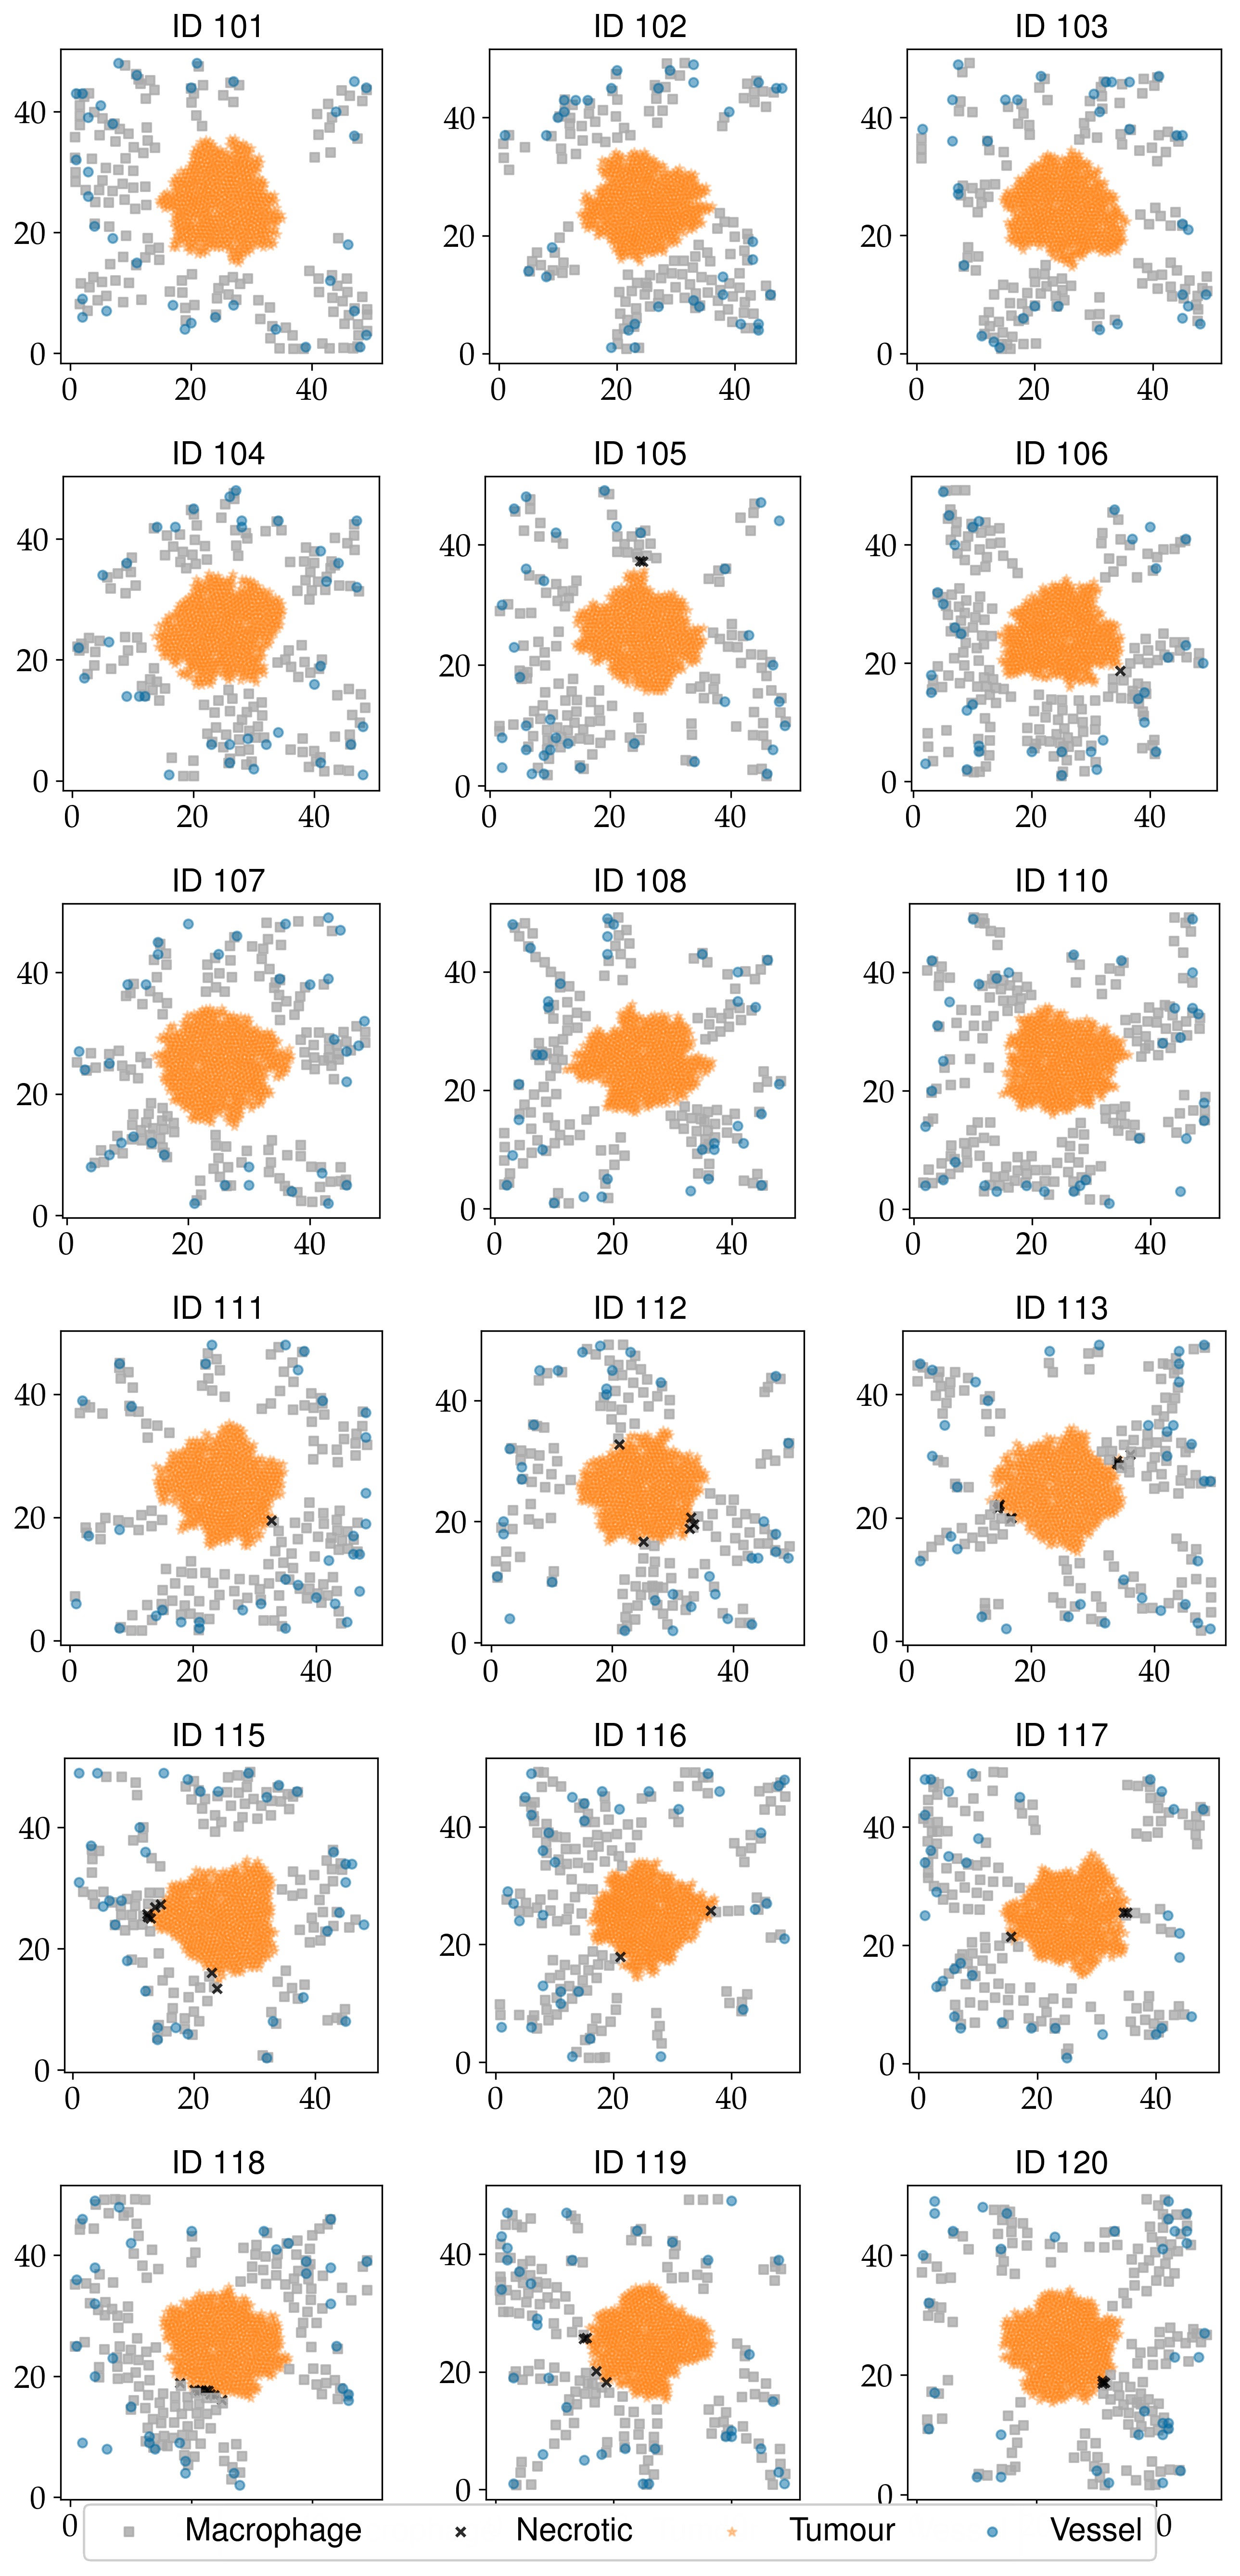

In [3]:
# Choosing the example for equilibrium (112)
show_plots(0.6, 0.5)

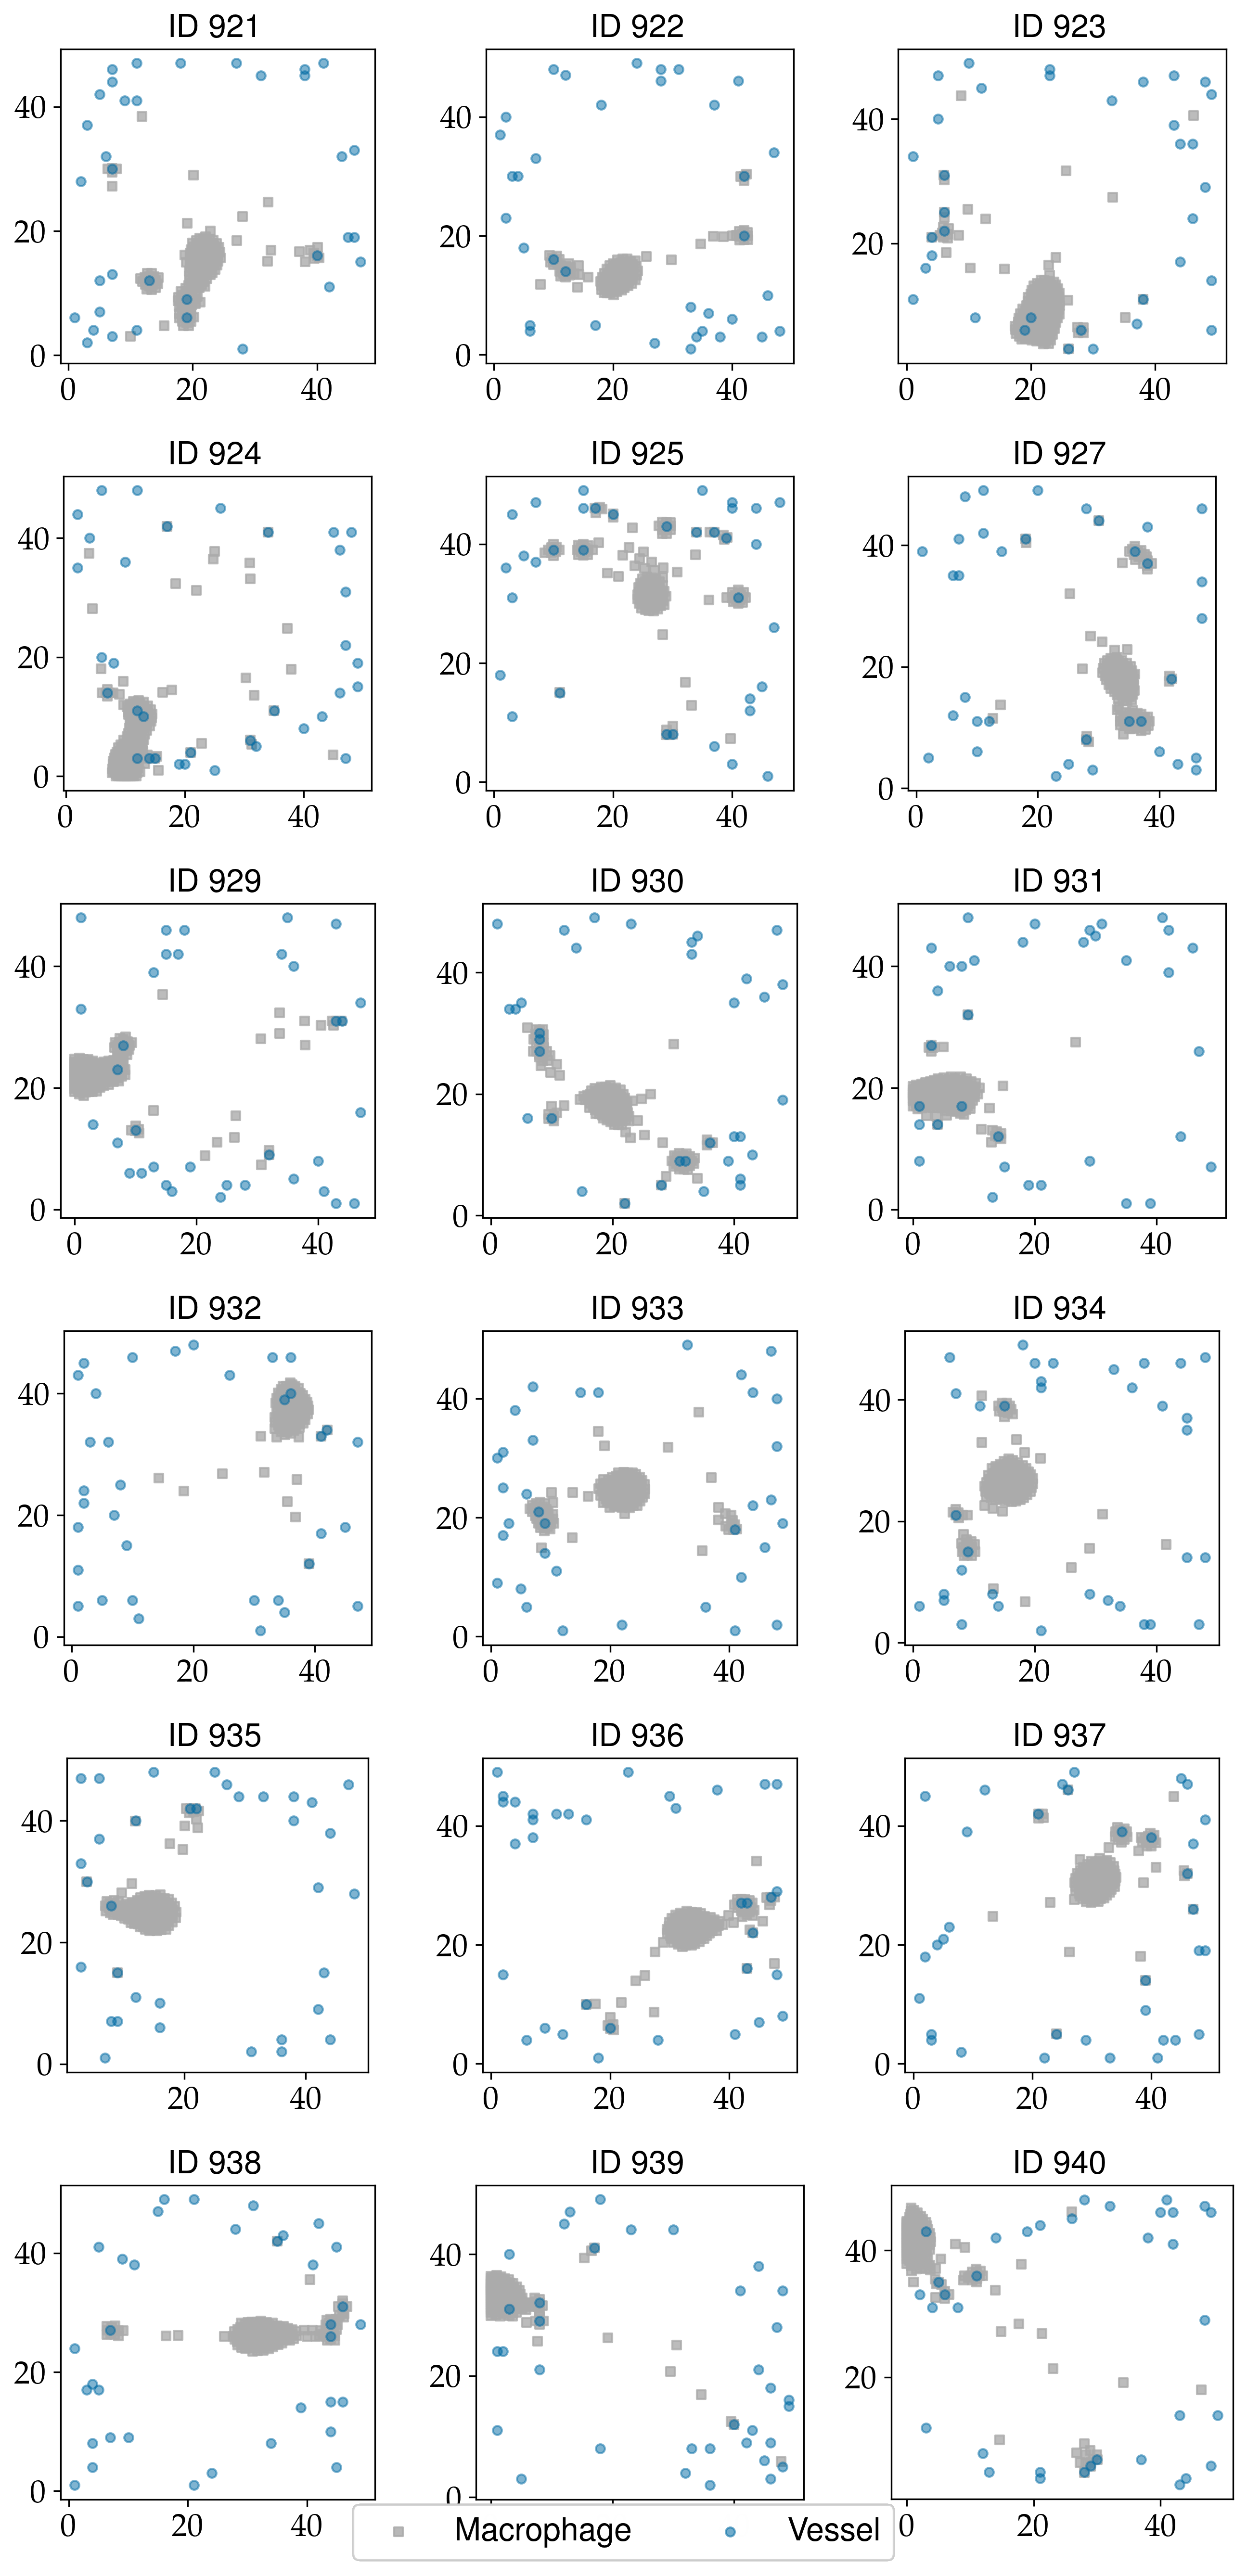

In [4]:
# Choosing the example for elimination (933)
show_plots(0.2, 3.0)

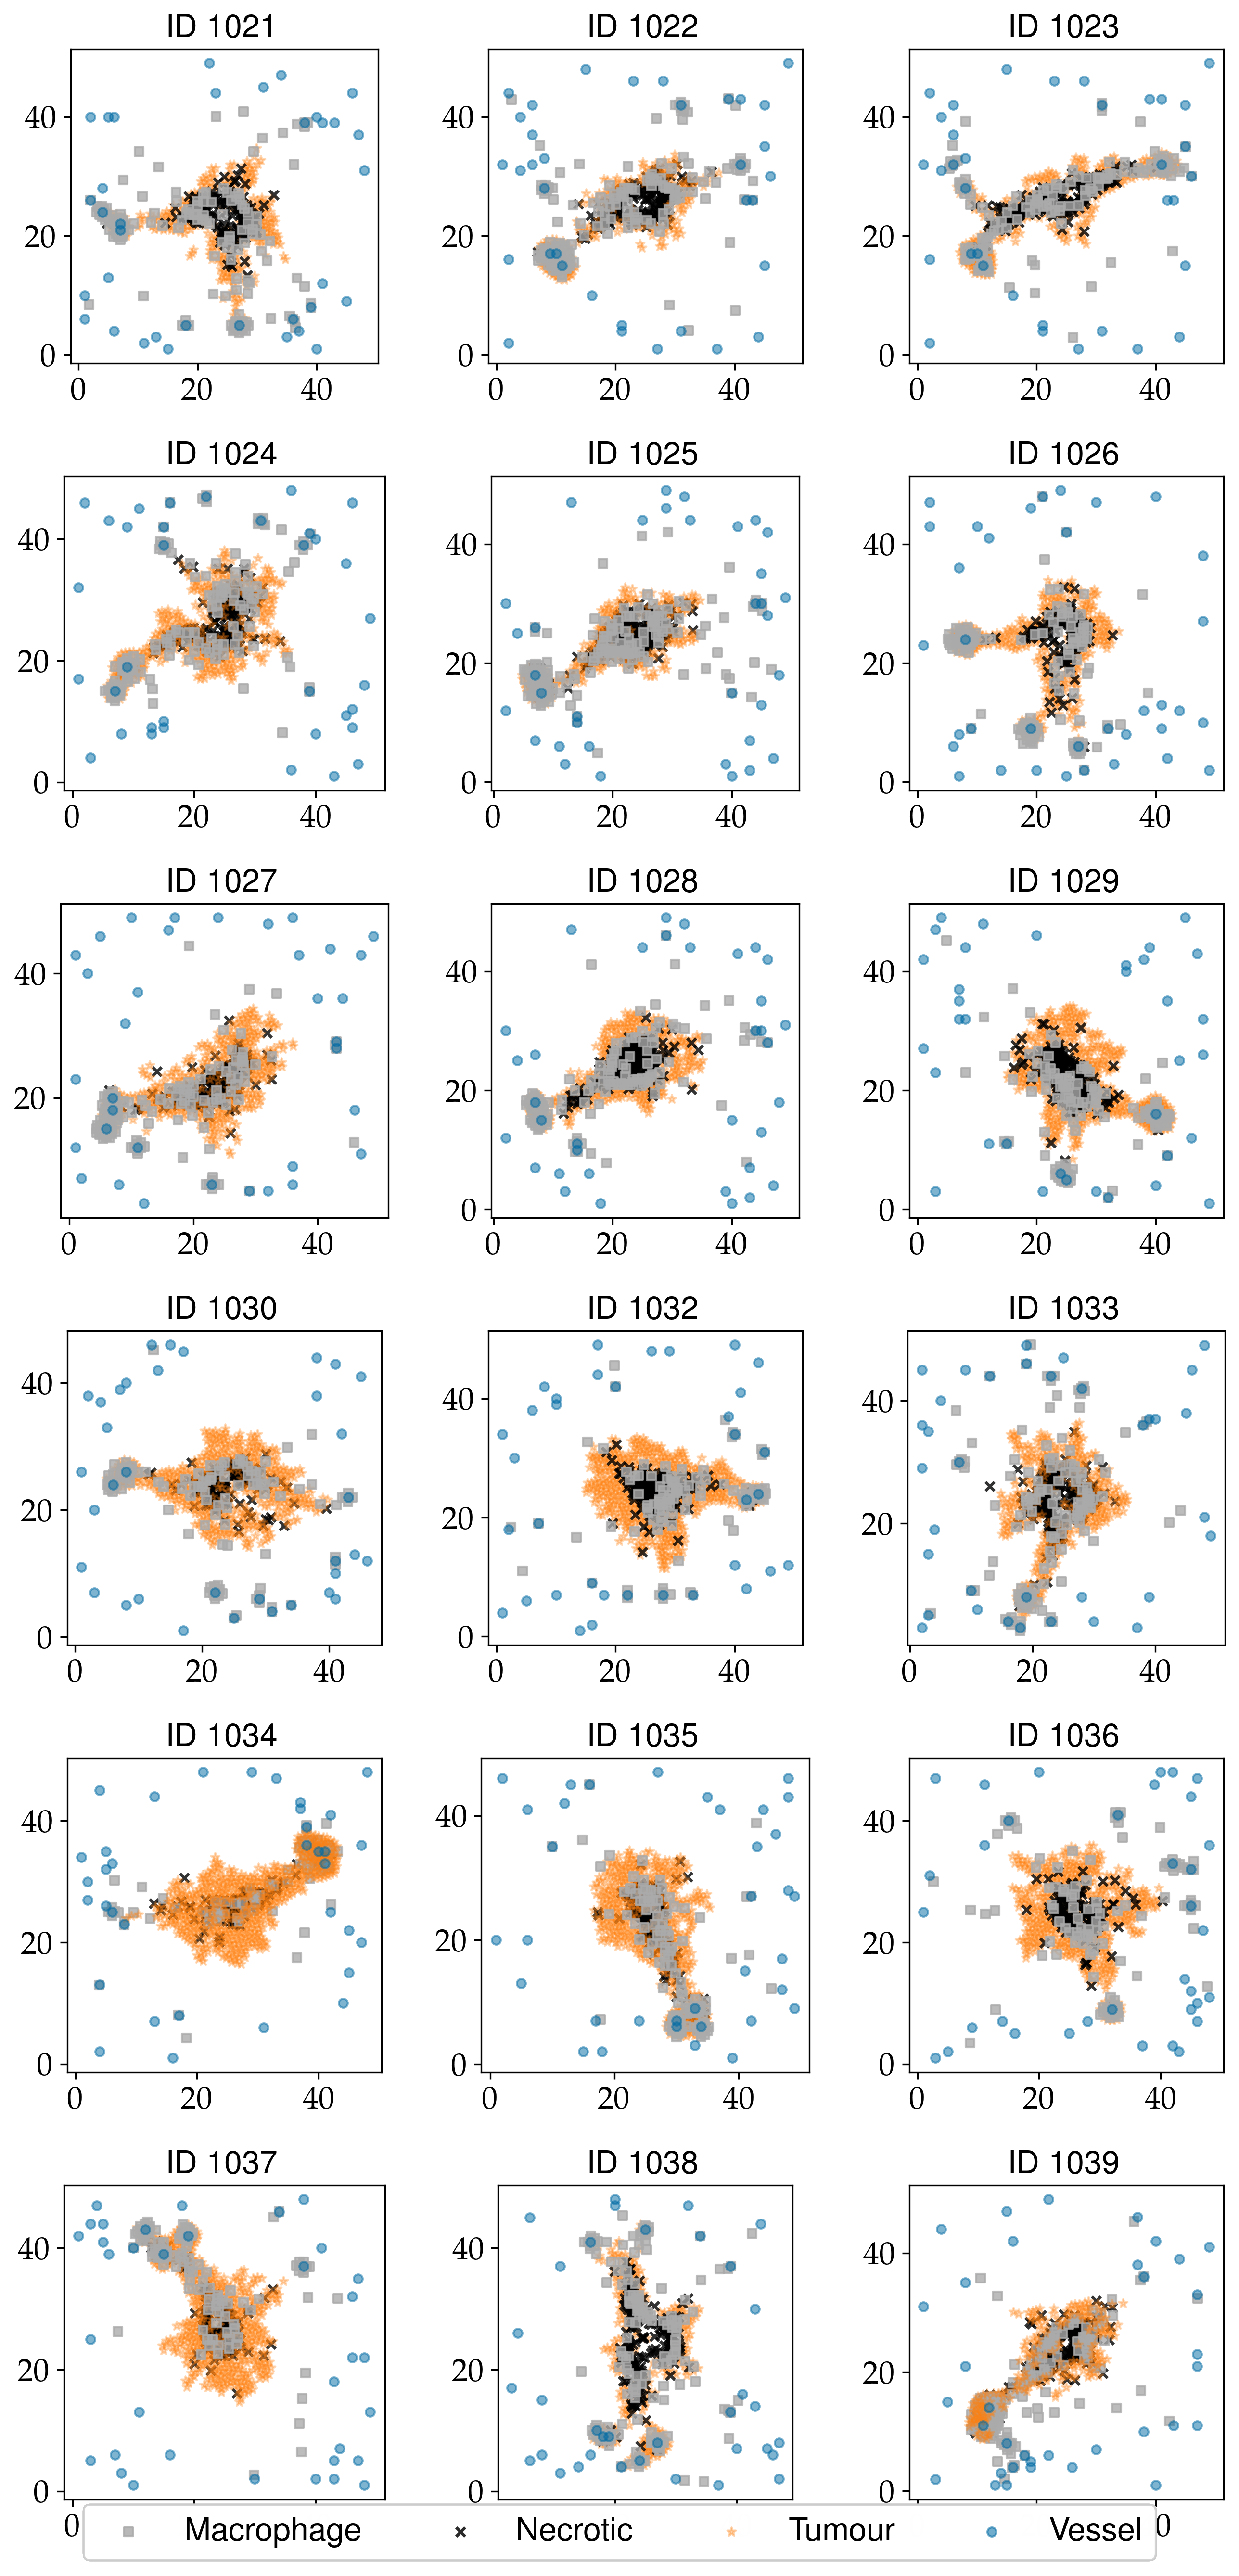

In [5]:
# Choosing the example for escape (1036)
show_plots(0.7, 3.0)

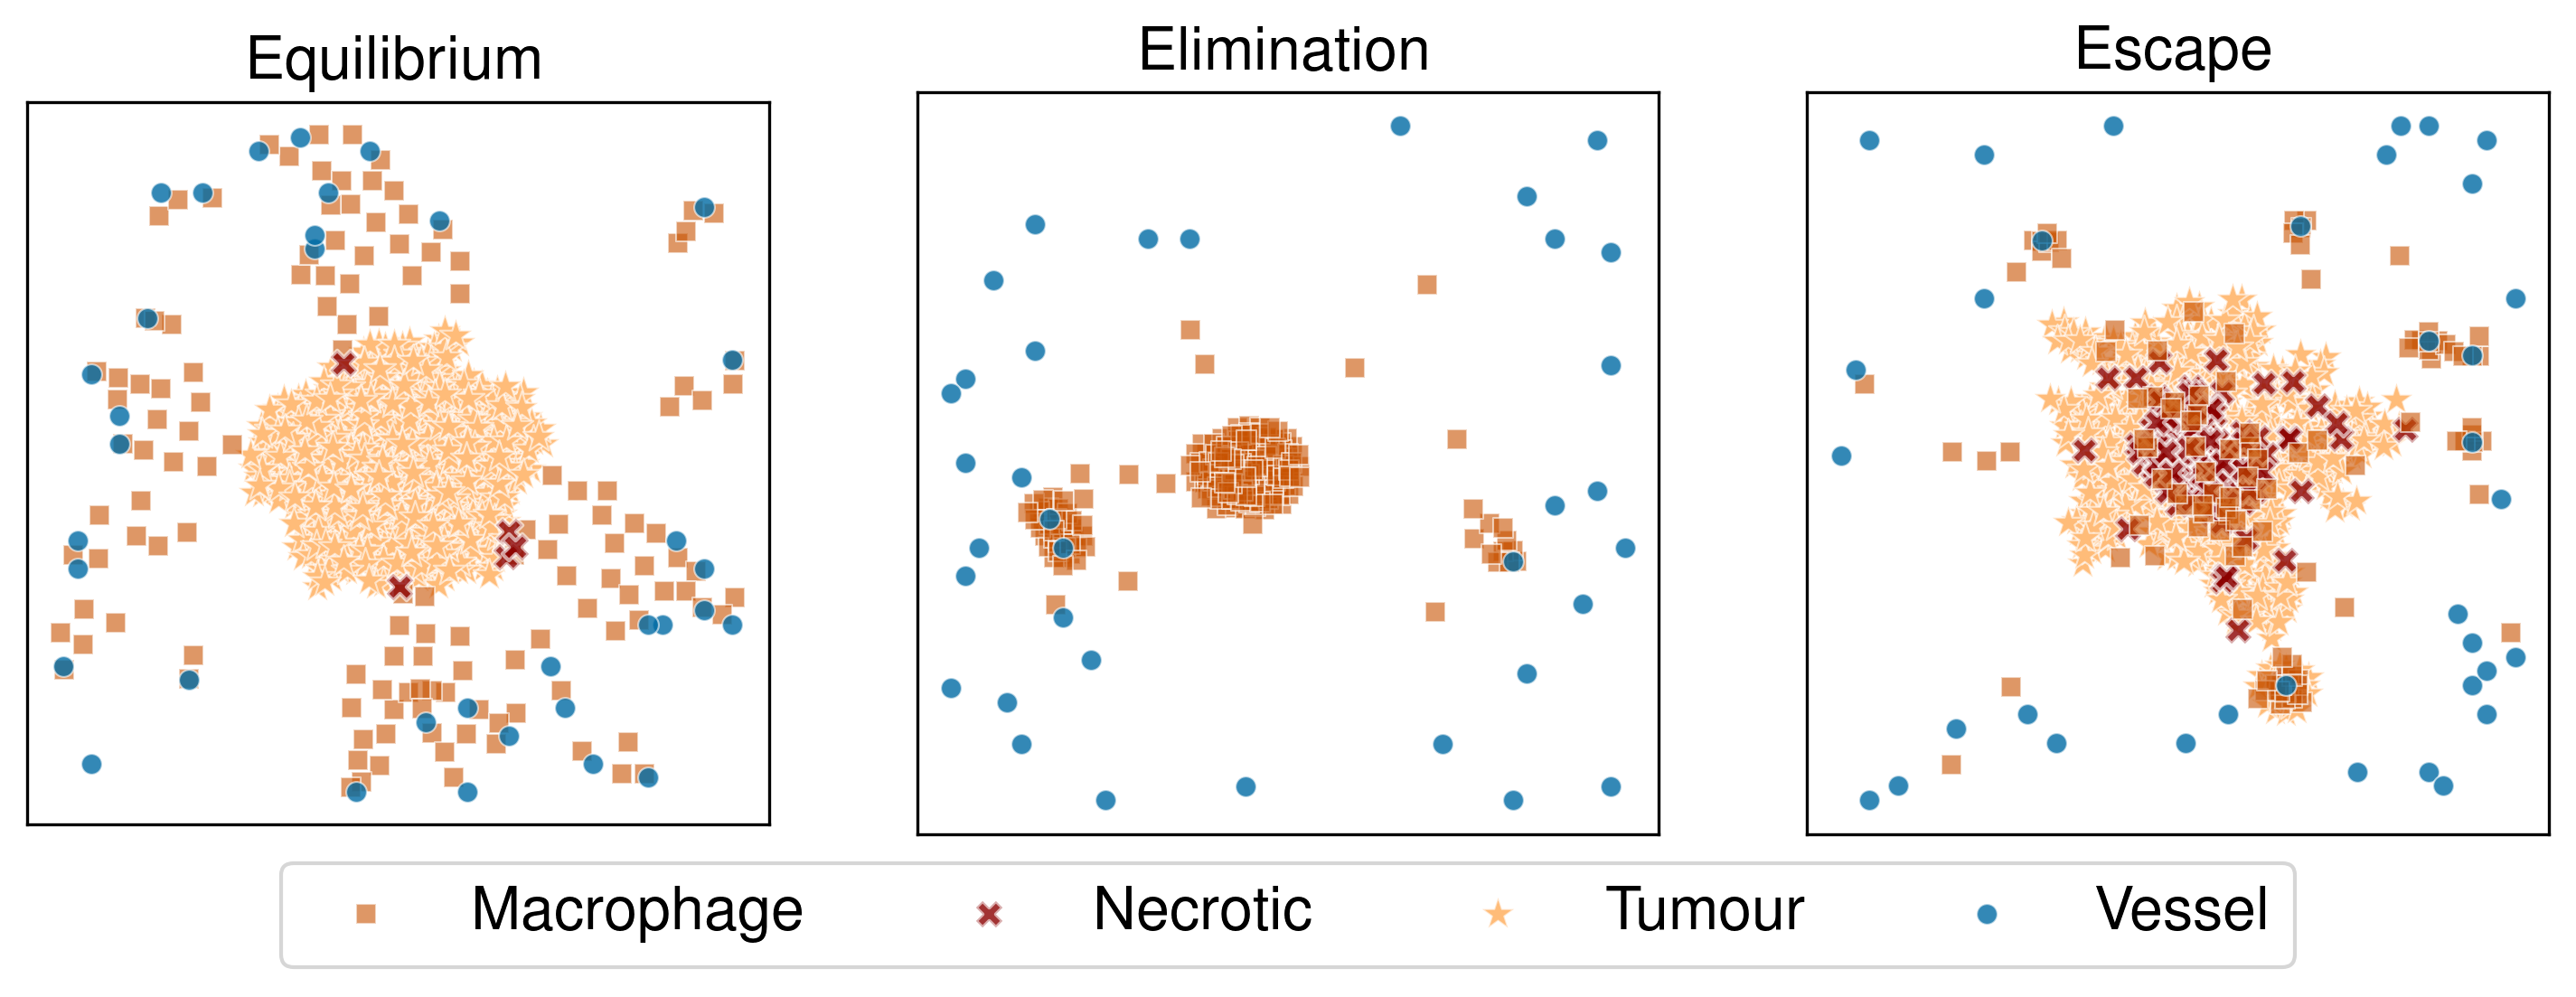

In [7]:
# Equilibrium 112
# Elimination 933
# Escape 1036

figsize = (12, 4)
kwargs = { 
        "Stroma" : { "c" : "C0", "marker" : ".", },
        "Vessel" : { 
            "facecolor" : mpl.colors.to_rgba("C0", 0.8),
            "edgecolor" : mpl.colors.to_rgba("white", 0.6),
            "marker" : "o",
            "linewidth" : 0.5
        },
        "Tumour" : { 
            "facecolor" : mpl.colors.to_rgba("C8"),
            "edgecolor" : mpl.colors.to_rgba("white", 0.6),
            "linewidth" : 0.5,
            "s" : 80,
            "marker" : "*"
        },
        "Macrophage" : { 
            "facecolor" : mpl.colors.to_rgba("C5", 0.6), 
            "edgecolor" : mpl.colors.to_rgba("white", 0.6),
            "linewidth" : 0.5,
            "marker" : "s", 
        },
        "Necrotic" : { 
            "facecolor" : mpl.colors.to_rgba("darkred", 0.8),
            "edgecolor" : mpl.colors.to_rgba("white", 0.6),
            "marker" : "X",
            "linewidth" : 1,
            "s" : 50
        },
      }
legends = {}
i = 0
fig, ax = plt.subplots(1, 3, figsize=figsize)
ax = ax.ravel()
for ID, regime in ((112, "Equilibrium"), (933, "Elimination"), (1036, "Escape")):
    filename = Path(f"../data/samples/ID-{ID}_time-500_From2ParamSweep_Data.csv").resolve()
    data = pl.read_csv(filename)
    for celltype in data["celltypes"].unique(maintain_order=True):
        if celltype == "Stroma":
            continue
        points = data.filter(pl.col("celltypes") == celltype).select("points_x", "points_y").to_numpy()
        
        ax[i].scatter(points[:, 0], points[:, 1], label=celltype, **({ "s" : 30 } | kwargs[celltype]))
        ax[i].set_title(f"{regime}")
        ax[i].set_aspect("equal")
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        handles, labels = ax[i].get_legend_handles_labels()
        legends |= dict(zip(labels, handles, strict=True))
    i += 1
# fig.tight_layout()
fig.subplots_adjust(hspace=10)
fig.legend(
    handles = [legends[key] for key in sorted(legends)],
    labels = sorted(legends),
    loc = "lower center",
    ncol = 4,
)
fig.savefig("figures/example_abm_regimes.pdf", bbox_inches="tight", pad_inches=0)
fig.savefig("figures/example_abm_regimes.svg", bbox_inches="tight", pad_inches=0)
plt.show()